# Exploratory Data Analysis of Ames Housing Dataset

**Submitted By:** Nischal Chandel

**URN:** E25B031568

**Course:** B.Tech Computer Science and Engineering

**Semester:** III

## Project Objective

The objective of this project is to perform Exploratory Data
Analysis (EDA) to understand the factors associated with house
sale prices using statistical methods and data visualization.

## Dataset Description

- Dataset: House Prices - Advanced Regression Techniques
- Source: Kaggle
- File: train.csv
- Target Variable: SalePrice
- Tools: Python, Pandas, NumPy, Matplotlib, Seaborn and SciPy

## Guiding Questions

1. How is SalePrice distributed? Is it skewed?
2. Which numerical features correlate most strongly with SalePrice?
3. Does overall quality change price in a clear, ordered way?
4. Do some neighborhoods consistently cost more than others?
5. Are there outliers, and are they errors or unusual sales?
6. Which columns have missing values, and which are not truly missing?

## Methodology

The project covers data understanding, descriptive statistics,
distribution analysis, correlation analysis, outlier detection,
data cleaning and dashboard visualization.

No machine learning models are used.

## 2. Data Understanding

We begin by importing the required libraries, loading the dataset,
examining its structure, identifying missing values and
classifying the variables.

In [15]:
# Import required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from google.colab import drive

# Plotting settings
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)

# Connect Google Drive and load dataset
drive.mount("/content/drive")

df = pd.read_csv("/content/drive/MyDrive/train.csv")

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

display(df.head())
df.info()

# Missing value analysis
missing = df.isnull().sum()

missing_summary = pd.DataFrame({
    "Missing Values": missing,
    "Missing Percentage (%)": (missing / len(df) * 100).round(2)
})

missing_summary = missing_summary[missing > 0]
missing_summary = missing_summary.sort_values(
    "Missing Values", ascending=False
)

print("\nColumns with Missing Values:", len(missing_summary))
display(missing_summary)

# Convert ordinal variables
quality_order = ["Po", "Fa", "TA", "Gd", "Ex"]

for col in ["ExterQual", "KitchenQual"]:
    df[col] = pd.Categorical(
        df[col], categories=quality_order, ordered=True
    )

# Classify variables
numerical_cols = df.select_dtypes(include="number").columns.tolist()

categorical_cols = df.select_dtypes(
    include=["object", "category"]
).columns.tolist()

print("\nNumerical Variables:", len(numerical_cols))
print("Categorical Variables:", len(categorical_cols))
print("Ordered Categorical Variables:", 2)

# Variable summary table
variable_summary = pd.DataFrame({
    "Column": df.columns,
    "Data Type": df.dtypes.astype(str).values,
    "Unique Values": df.nunique().values,
    "Examples": [
        df[col].dropna().unique()[:5].tolist()
        for col in df.columns
    ]
})

display(variable_summary)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Dataset loaded successfully!
Dataset Shape: (1460, 81)


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   object 
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   object 
 6   Alley          91 non-null     object 
 7   LotShape       1460 non-null   object 
 8   LandContour    1460 non-null   object 
 9   Utilities      1460 non-null   object 
 10  LotConfig      1460 non-null   object 
 11  LandSlope      1460 non-null   object 
 12  Neighborhood   1460 non-null   object 
 13  Condition1     1460 non-null   object 
 14  Condition2     1460 non-null   object 
 15  BldgType       1460 non-null   object 
 16  HouseStyle     1460 non-null   object 
 17  OverallQual    1460 non-null   int64  
 18  OverallC

,Missing Values,Missing Percentage (%)
PoolQC,1453,99.52
MiscFeature,1406,96.30
Alley,1369,93.77
Fence,1179,80.75
MasVnrType,872,59.73
FireplaceQu,690,47.26
LotFrontage,259,17.74
GarageType,81,5.55
GarageYrBlt,81,5.55
GarageFinish,81,5.55



Numerical Variables: 38
Categorical Variables: 43
Ordered Categorical Variables: 2


,Column,Data Type,Unique Values,Examples
0,Id,int64,1460,"[1, 2, 3, 4, 5]"
1,MSSubClass,int64,15,"[60, 20, 70, 50, 190]"
2,MSZoning,object,5,"[RL, RM, C (all), FV, RH]"
3,LotFrontage,float64,110,"[65.0, 80.0, 68.0, 60.0, 84.0]"
4,LotArea,int64,1073,"[8450, 9600, 11250, 9550, 14260]"
...,...,...,...,...
76,MoSold,int64,12,"[2, 5, 9, 12, 10]"
77,YrSold,int64,5,"[2008, 2007, 2006, 2009, 2010]"
78,SaleType,object,9,"[WD, New, COD, ConLD, ConLI]"
79,SaleCondition,object,6,"[Normal, Abnorml, Partial, AdjLand, Alloca]"


### Data Understanding - Observations

- The dataset contains 1,460 rows and 81 columns.
- There are 38 numerical and 43 categorical variables,
  including two ordered categorical variables.
- A total of 19 columns contain missing values.
- PoolQC, MiscFeature, Alley and Fence contain a large
  number of missing values.
- Some missing values represent the absence of a feature
  rather than missing information.
- ExterQual and KitchenQual are converted into ordered
  categorical variables.
- OverallQual is stored numerically but represents an ordinal quality rating.
- Id is a unique record identifier rather than a numerical measurement.
- MSSubClass is stored numerically but represents a categorical building classification.
## 3. Descriptive Statistics and Distribution Analysis

We calculate statistical measures to understand the centre,
spread and shape of numerical variables. We also examine
categorical frequencies and visualize important distributions.

,Id,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,...,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SalePrice
count,1460.00,1460.0,1201.00,1460.00,1460.00,1460.00,1460.00,1460.00,1452.00,1460.00,...,1460.00,1460.00,1460.00,1460.00,1460.00,1460.00,1460.00,1460.00,1460.00,1460.0
mean,730.50,56.9,70.05,10516.83,6.10,5.58,1971.27,1984.87,103.69,443.64,...,94.24,46.66,21.95,3.41,15.06,2.76,43.49,6.32,2007.82,180921.2
std,421.61,42.3,24.28,9981.26,1.38,1.11,30.20,20.65,181.07,456.10,...,125.34,66.26,61.12,29.32,55.76,40.18,496.12,2.70,1.33,79442.5
min,1.00,20.0,21.00,1300.00,1.00,1.00,1872.00,1950.00,0.00,0.00,...,0.00,0.00,0.00,0.00,0.00,0.00,0.00,1.00,2006.00,34900.0
25%,365.75,20.0,59.00,7553.50,5.00,5.00,1954.00,1967.00,0.00,0.00,...,0.00,0.00,0.00,0.00,0.00,0.00,0.00,5.00,2007.00,129975.0
50%,730.50,50.0,69.00,9478.50,6.00,5.00,1973.00,1994.00,0.00,383.50,...,0.00,25.00,0.00,0.00,0.00,0.00,0.00,6.00,2008.00,163000.0
75%,1095.25,70.0,80.00,11601.50,7.00,6.00,2000.00,2004.00,166.00,712.25,...,168.00,68.00,0.00,0.00,0.00,0.00,0.00,8.00,2009.00,214000.0
max,1460.00,190.0,313.00,215245.00,10.00,9.00,2010.00,2010.00,1600.00,5644.00,...,857.00,547.00,552.00,508.00,480.00,738.00,15500.00,12.00,2010.00,755000.0


,SalePrice,GrLivArea,LotArea
Mean,"180,921.20","1,515.46","10,516.83"
Median,"163,000.00","1,464.00","9,478.50"
Mode,"140,000.00",864.00,"7,200.00"
Standard Deviation,"79,442.50",525.48,"9,981.26"
Variance,"6,311,111,264.30","276,129.63","99,625,649.65"
Minimum,"34,900.00",334.00,"1,300.00"
Maximum,"755,000.00","5,642.00","215,245.00"
Range,"720,100.00","5,308.00","213,945.00"
Q1,"129,975.00","1,129.50","7,553.50"
Q3,"214,000.00","1,776.75","11,601.50"



Frequency Distribution: Neighborhood


,Count
Neighborhood,
NAmes,225
CollgCr,150
OldTown,113
Edwards,100
Somerst,86
Gilbert,79
NridgHt,77
Sawyer,74
NWAmes,73


Most Common Category: NAmes

Frequency Distribution: HouseStyle


,Count
HouseStyle,
1Story,726
2Story,445
1.5Fin,154
SLvl,65
SFoyer,37
1.5Unf,14
2.5Unf,11
2.5Fin,8


Most Common Category: 1Story


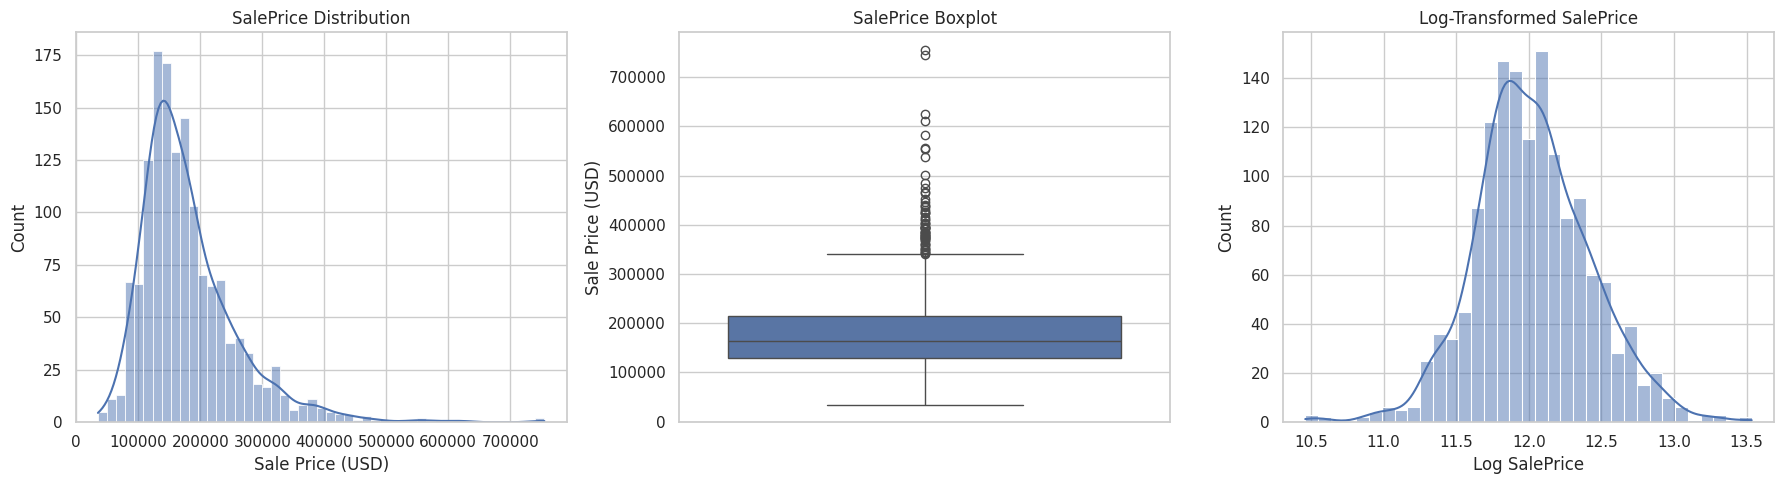

Original Skewness: 1.883
Log-Transformed Skewness: 0.121


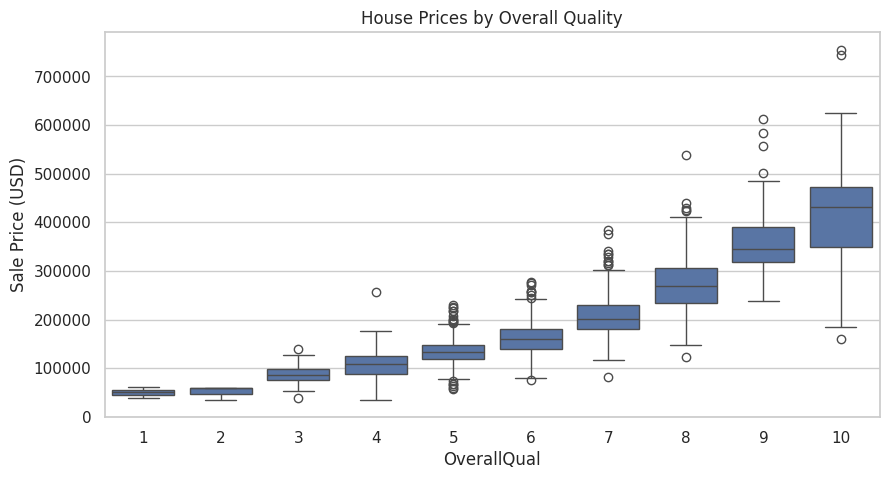

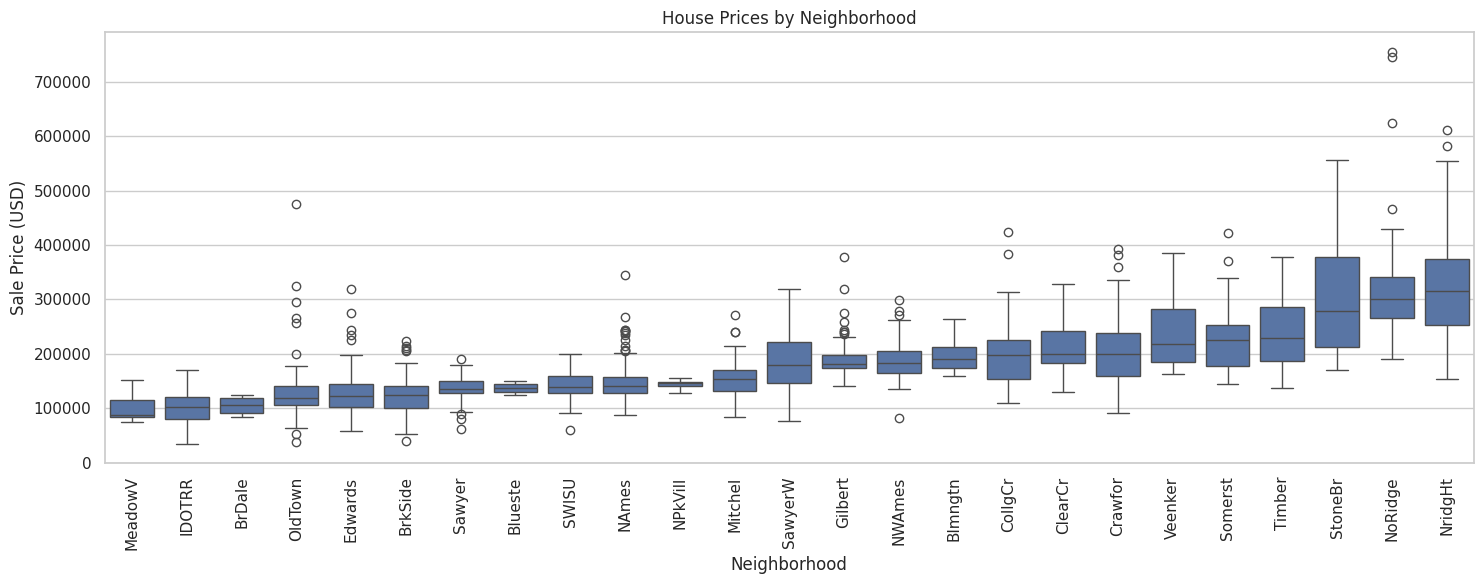

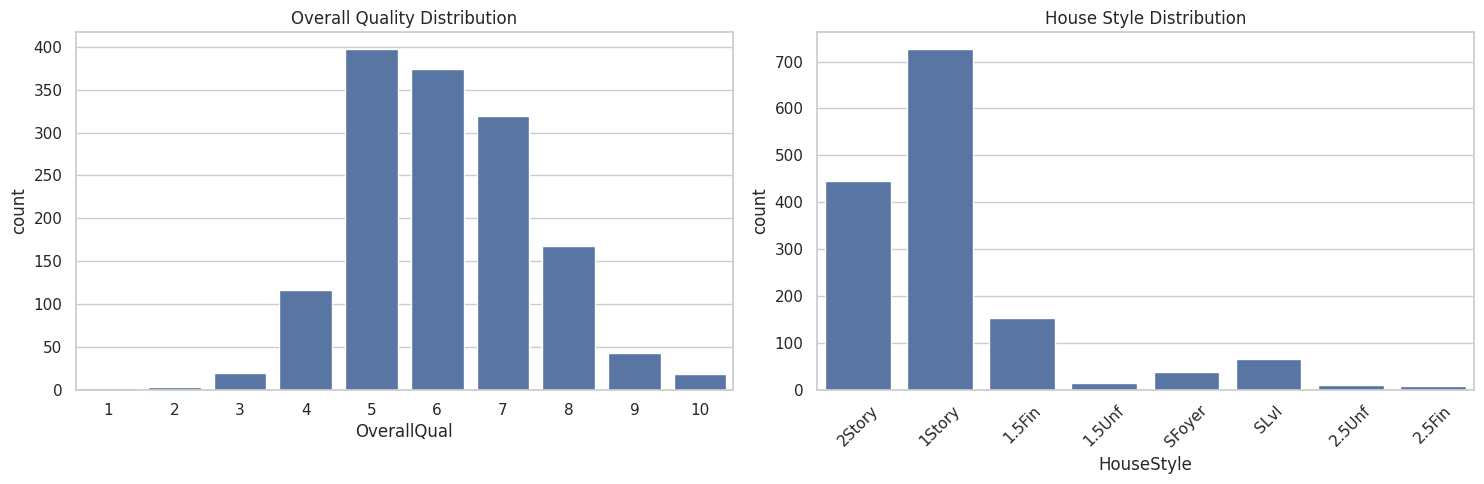

In [16]:
# General descriptive statistics
display(df.describe().round(2))

# Detailed statistical analysis
selected = ["SalePrice", "GrLivArea", "LotArea"]
data = df[selected]

summary = pd.DataFrame({
    "Mean": data.mean(),
    "Median": data.median(),
    "Mode": data.mode().iloc[0],
    "Standard Deviation": data.std(),
    "Variance": data.var(),
    "Minimum": data.min(),
    "Maximum": data.max(),
    "Range": data.max() - data.min(),
    "Q1": data.quantile(0.25),
    "Q3": data.quantile(0.75),
    "IQR": data.quantile(0.75) - data.quantile(0.25),
    "Skewness": data.skew(),
    "Kurtosis": data.kurt()
})

display(summary.T.style.format("{:,.2f}"))

# Categorical frequency analysis
for col in ["Neighborhood", "HouseStyle"]:
    print("\nFrequency Distribution:", col)
    display(df[col].value_counts().to_frame("Count"))
    print("Most Common Category:", df[col].mode()[0])

# SalePrice distribution
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.histplot(df["SalePrice"], kde=True, ax=axes[0])
axes[0].set_title("SalePrice Distribution")
axes[0].set_xlabel("Sale Price (USD)")

sns.boxplot(y=df["SalePrice"], ax=axes[1])
axes[1].set_title("SalePrice Boxplot")
axes[1].set_ylabel("Sale Price (USD)")

log_price = np.log(df["SalePrice"])

sns.histplot(log_price, kde=True, ax=axes[2])
axes[2].set_title("Log-Transformed SalePrice")
axes[2].set_xlabel("Log SalePrice")

plt.tight_layout()
plt.show()

print("Original Skewness:", round(df["SalePrice"].skew(), 3))
print("Log-Transformed Skewness:", round(log_price.skew(), 3))

# Overall quality vs SalePrice
plt.figure(figsize=(10, 5))
sns.boxplot(data=df, x="OverallQual", y="SalePrice")
plt.title("House Prices by Overall Quality")
plt.ylabel("Sale Price (USD)")
plt.show()

# Neighborhood vs SalePrice
neighborhood_order = df.groupby("Neighborhood")[
    "SalePrice"
].median().sort_values().index

plt.figure(figsize=(15, 6))
sns.boxplot(
    data=df, x="Neighborhood", y="SalePrice",
    order=neighborhood_order
)
plt.title("House Prices by Neighborhood")
plt.ylabel("Sale Price (USD)")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

# Categorical countplots
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.countplot(data=df, x="OverallQual", ax=axes[0])
axes[0].set_title("Overall Quality Distribution")

sns.countplot(data=df, x="HouseStyle", ax=axes[1])
axes[1].set_title("House Style Distribution")
axes[1].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

### Statistical and Distribution Analysis - Observations

- The average SalePrice is approximately $180,921,
  while the median is $163,000.
- The higher mean and positive skewness of 1.88 indicate
  that SalePrice is right-skewed.
- Log transformation reduces skewness to approximately 0.12,
  making the distribution more symmetric.
- LotArea has a high skewness of 12.21, indicating
  unusually large lots.
- NAmes is the most common neighborhood, with 225 houses.
- 1Story is the most common house style, with 726 houses.
- House prices generally increase with OverallQual.
- Higher-quality houses show greater variation in prices.
- Neighborhoods have noticeably different median prices.

## 4. Correlation and Relationship Analysis

We use Pearson correlation, covariance, scatterplots,
pairplots and a correlation heatmap to identify relationships
between house features and SalePrice.

Top 10 Features Correlated with SalePrice:


,Correlation
OverallQual,0.7910
GrLivArea,0.7086
GarageCars,0.6404
GarageArea,0.6234
TotalBsmtSF,0.6136
1stFlrSF,0.6059
FullBath,0.5607
TotRmsAbvGrd,0.5337
YearBuilt,0.5229
YearRemodAdd,0.5071


,Covariance,Correlation
OverallQual,8.690413e+04,0.790982
GrLivArea,2.958187e+07,0.708624
GarageCars,3.802018e+04,0.640409


GarageArea and GarageCars Correlation: 0.8825


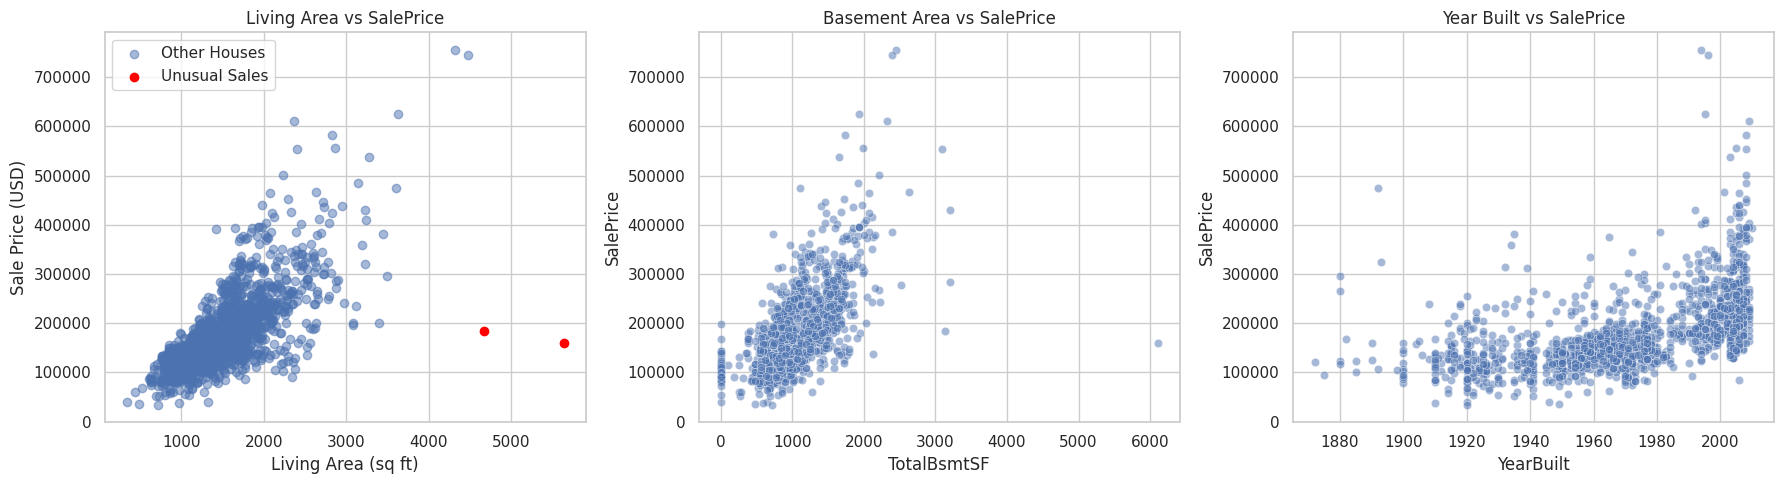

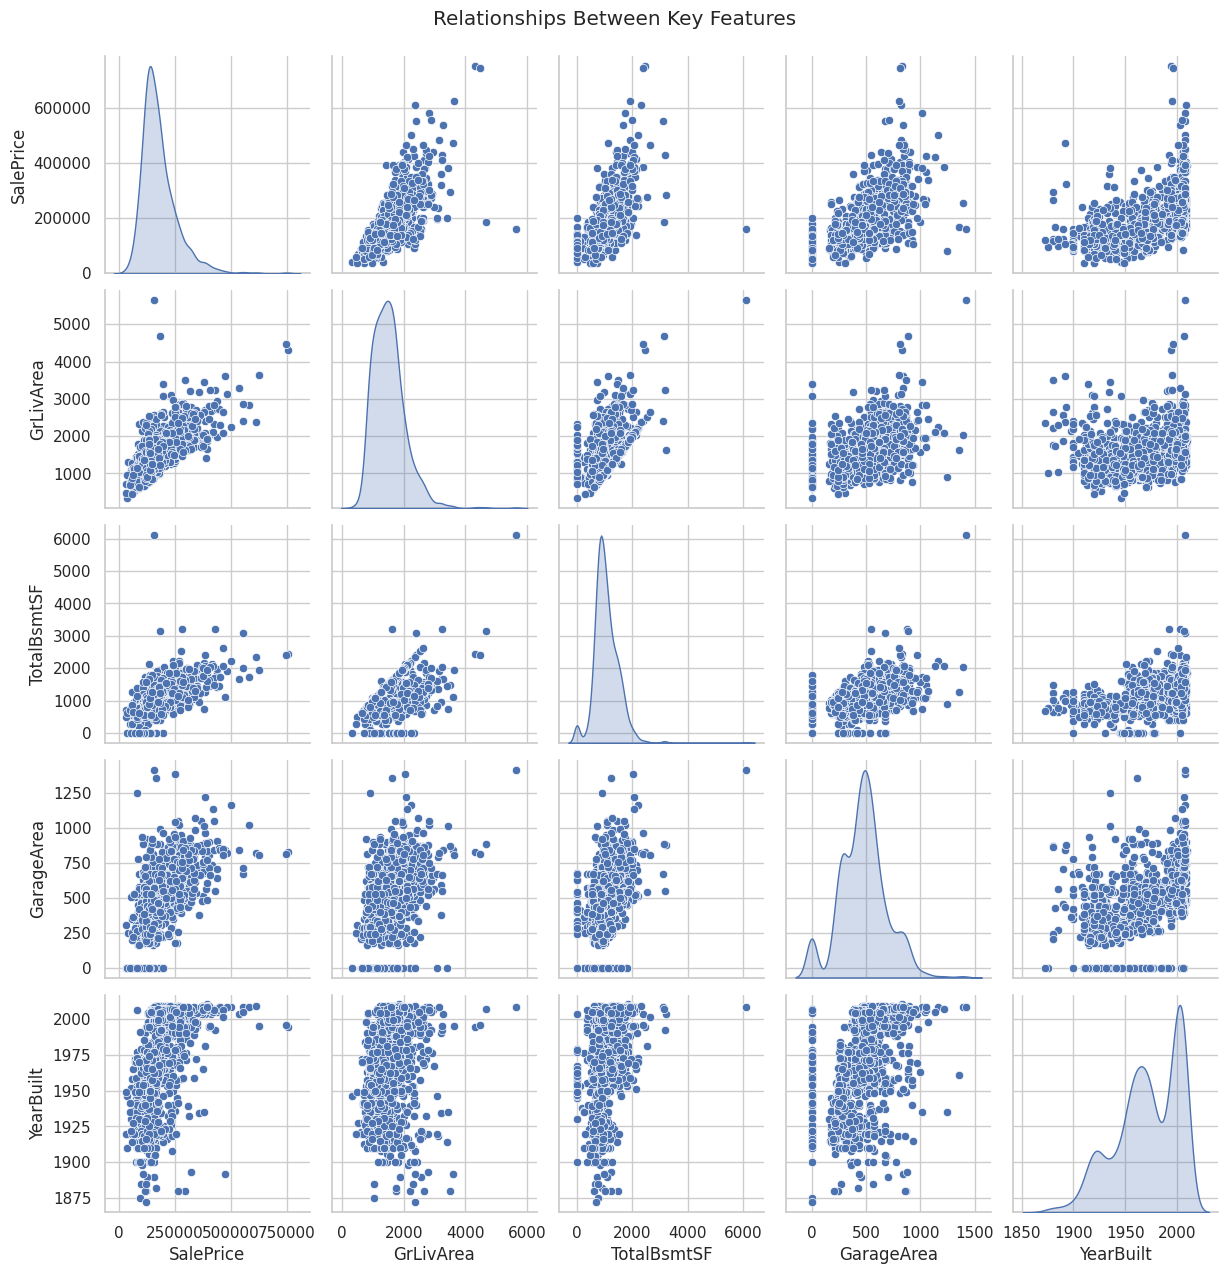

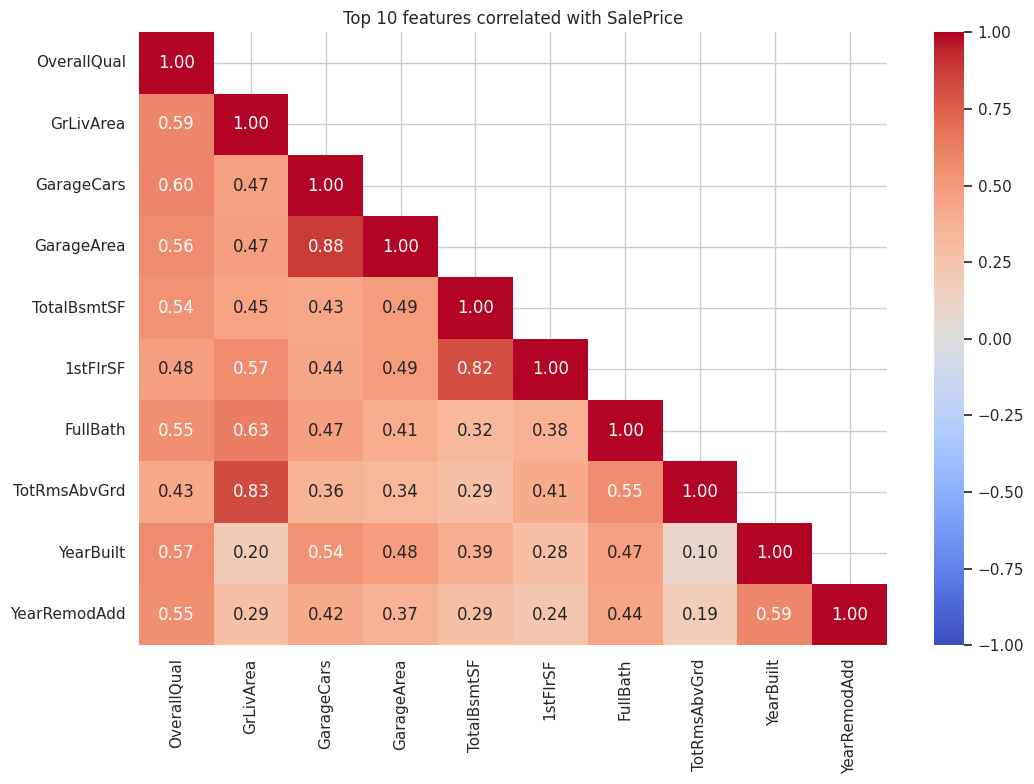

In [17]:
# Correlation and covariance matrices
numeric_data = df.select_dtypes(include="number")

corr_matrix = numeric_data.corr(method="pearson")
cov_matrix = numeric_data.cov()

# Top 10 features correlated with SalePrice
price_corr = corr_matrix["SalePrice"].drop("SalePrice")

top10 = price_corr.abs().sort_values(
    ascending=False
).head(10).index

print("Top 10 Features Correlated with SalePrice:")
display(price_corr.loc[top10].to_frame("Correlation").round(4))

# Covariance and correlation of top 3 features
top3 = top10[:3]

comparison = pd.DataFrame({
    "Covariance": cov_matrix.loc[top3, "SalePrice"],
    "Correlation": corr_matrix.loc[top3, "SalePrice"]
})

display(comparison)

print("GarageArea and GarageCars Correlation:",
      round(corr_matrix.loc["GarageArea", "GarageCars"], 4))

# Identify unusually large and low-priced houses
unusual = (df["GrLivArea"] > 4000) & (df["SalePrice"] < 200000)

# Scatterplots
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

axes[0].scatter(
    df.loc[~unusual, "GrLivArea"],
    df.loc[~unusual, "SalePrice"],
    alpha=0.5, label="Other Houses"
)

axes[0].scatter(
    df.loc[unusual, "GrLivArea"],
    df.loc[unusual, "SalePrice"],
    color="red", label="Unusual Sales"
)

axes[0].set_title("Living Area vs SalePrice")
axes[0].set_xlabel("Living Area (sq ft)")
axes[0].set_ylabel("Sale Price (USD)")
axes[0].legend()

sns.scatterplot(
    data=df, x="TotalBsmtSF", y="SalePrice",
    alpha=0.5, ax=axes[1]
)
axes[1].set_title("Basement Area vs SalePrice")

sns.scatterplot(
    data=df, x="YearBuilt", y="SalePrice",
    alpha=0.5, ax=axes[2]
)
axes[2].set_title("Year Built vs SalePrice")

plt.tight_layout()
plt.show()

# Pairplot
pair_columns = [
    "SalePrice", "GrLivArea", "TotalBsmtSF",
    "GarageArea", "YearBuilt"
]

g = sns.pairplot(df[pair_columns], diag_kind="kde")
g.fig.suptitle("Relationships Between Key Features", y=1.02)
plt.show()

# Correlation heatmap
corr_top = df[top10].corr()
mask = np.triu(np.ones_like(corr_top, dtype=bool), k=1)

plt.figure(figsize=(11, 8))

sns.heatmap(
    corr_top,
    mask=mask,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1
)

plt.title("Top 10 features correlated with SalePrice")
plt.tight_layout()
plt.show()

### Correlation and Relationship Analysis - Observations

- OverallQual has the strongest correlation with SalePrice
  (approximately 0.79).
- GrLivArea has the second strongest correlation (0.71),
  followed by GarageCars (0.64).
- Correlation is easier to compare than covariance because
  it is standardized between -1 and +1.
- GarageArea and GarageCars have a strong correlation
  of approximately 0.88, suggesting overlapping information.
- Larger living areas and basement areas are generally
  associated with higher house prices.
- Newer houses generally have higher selling prices.
- Two unusually large houses have unexpectedly low prices.
- The heatmap reveals relationships between numerical features.
- Correlation indicates association, not causation.

## 5. Outlier Detection and Data Cleaning

We detect outliers using the IQR and Z-score methods,
compare their results and examine unusual sales before
making data cleaning decisions.

,Variable,IQR Outliers,Z-score Outliers,Overlap
0,GrLivArea,31,16,16
1,SalePrice,61,22,22


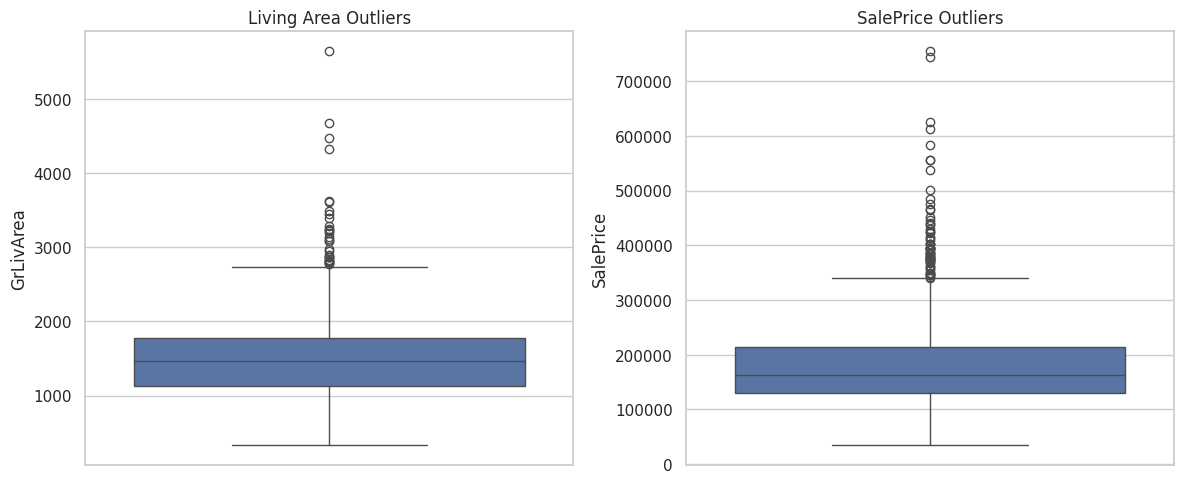

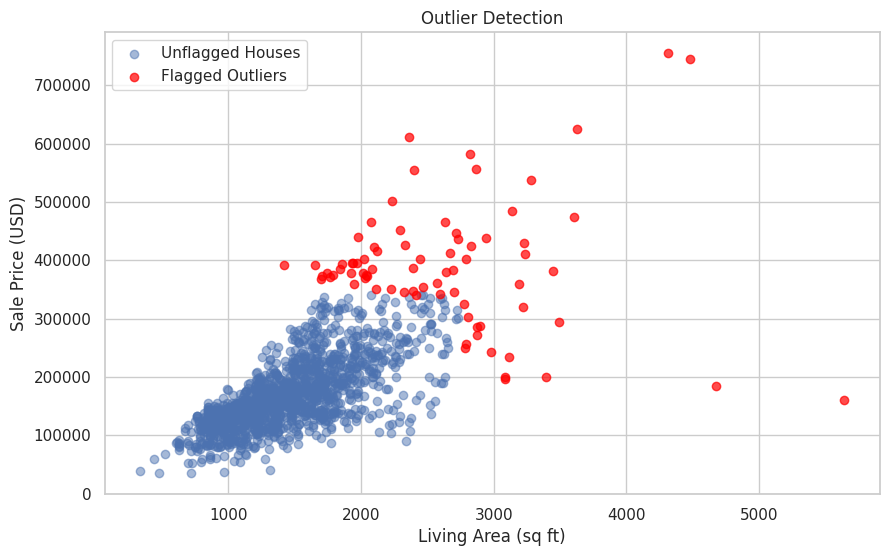

Unusually Large and Low-Priced Houses:


,Id,GrLivArea,SalePrice,OverallQual,Neighborhood,SaleCondition
523,524,4676,184750,10,Edwards,Partial
1298,1299,5642,160000,10,Edwards,Partial


Original Shape: (1460, 81)
Cleaned Shape: (1458, 81)
Rows Removed: 2
Correlation Before Outlier Removal: 0.7086
Correlation After Outlier Removal: 0.735


In [18]:
# IQR outlier detection
def iqr_outliers(series):
    q1 = series.quantile(0.25)
    q3 = series.quantile(0.75)
    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    return (series < lower) | (series > upper)

# Z-score outlier detection
def zscore_outliers(series):
    return np.abs(stats.zscore(series)) > 3

# Compare both methods
outlier_results = []

for col in ["GrLivArea", "SalePrice"]:
    a = iqr_outliers(df[col])
    b = zscore_outliers(df[col])

    outlier_results.append({
        "Variable": col,
        "IQR Outliers": a.sum(),
        "Z-score Outliers": b.sum(),
        "Overlap": (a & b).sum()
    })

display(pd.DataFrame(outlier_results))

# Boxplots
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.boxplot(y=df["GrLivArea"], ax=axes[0])
axes[0].set_title("Living Area Outliers")

sns.boxplot(y=df["SalePrice"], ax=axes[1])
axes[1].set_title("SalePrice Outliers")

plt.tight_layout()
plt.show()

# Highlight all observations flagged by either method
flagged = (
    iqr_outliers(df["GrLivArea"]) |
    iqr_outliers(df["SalePrice"]) |
    zscore_outliers(df["GrLivArea"]) |
    zscore_outliers(df["SalePrice"])
)

plt.figure(figsize=(10, 6))

plt.scatter(
    df.loc[~flagged, "GrLivArea"],
    df.loc[~flagged, "SalePrice"],
    alpha=0.5, label="Unflagged Houses"
)

plt.scatter(
    df.loc[flagged, "GrLivArea"],
    df.loc[flagged, "SalePrice"],
    color="red", alpha=0.7, label="Flagged Outliers"
)

plt.xlabel("Living Area (sq ft)")
plt.ylabel("Sale Price (USD)")
plt.title("Outlier Detection")
plt.legend()
plt.show()

# Examine unusual sales
print("Unusually Large and Low-Priced Houses:")

display(df.loc[unusual, [
    "Id", "GrLivArea", "SalePrice",
    "OverallQual", "Neighborhood", "SaleCondition"
]])

# Create cleaned dataset
df_clean = df.loc[~unusual].copy()

print("Original Shape:", df.shape)
print("Cleaned Shape:", df_clean.shape)
print("Rows Removed:", len(df) - len(df_clean))
# Compare correlation before and after outlier removal
print("Correlation Before Outlier Removal:",
      round(df["GrLivArea"].corr(df["SalePrice"]), 4))

print("Correlation After Outlier Removal:",
      round(df_clean["GrLivArea"].corr(df_clean["SalePrice"]), 4))

### Outlier Detection - Observations

- For GrLivArea, the IQR method detects 31 outliers,
  while the Z-score method detects 16.
- For SalePrice, the IQR method detects 61 outliers,
  while the Z-score method detects 22.
- The Z-score method detects fewer outliers because extreme
  values can increase the mean and standard deviation.
- Two houses have living areas above 4,000 square feet
  but selling prices below $200,000.
- These observations may represent unusual sales rather
  than confirmed data errors.
- They are excluded from the cleaned dataset to reduce
  their influence on the final dashboard.
- Other outliers are retained because extreme values
  may represent genuine house sales.
- The cleaned dataset contains 1,458 rows.
- After removing the two unusual sales, the correlation between GrLivArea and SalePrice increased from 0.7086 to 0.7350, indicating a stronger linear relationship.

### Data Quality and Missing Value Treatment

Next, we check duplicate records, inconsistent categorical
labels, missing values and impossible numerical values.

Missing values representing absent features are replaced
with "None", while genuinely unknown categorical values
are treated separately. Numerical missing values are
handled using appropriate zero values or median imputation.

In [19]:
# Check and remove duplicate records
print("Duplicate Rows:", df_clean.duplicated().sum())
df_clean = df_clean.drop_duplicates()

# Inspect categorical labels
for col in categorical_cols:
    values = df_clean[col].dropna().astype(str).unique()

    print(col, ":", values.tolist())

    # Check unnecessary spaces
    if any(v != v.strip() for v in values):
        df_clean[col] = df_clean[col].str.strip()
        print("Extra spaces removed.")

    # Check inconsistent casing
    if len(set(v.lower() for v in values)) < len(values):
        df_clean[col] = df_clean[col].str.lower()
        print("Inconsistent casing corrected.")

# Missing values representing absent features
absence_cols = ["PoolQC", "Alley", "Fence", "MiscFeature"]

for col in absence_cols:
    df_clean[col] = df_clean[col].fillna("None")

# Garage, basement and fireplace information
feature_groups = {
    "GarageArea": [
        "GarageType", "GarageFinish",
        "GarageQual", "GarageCond"
    ],
    "TotalBsmtSF": [
        "BsmtQual", "BsmtCond", "BsmtExposure",
        "BsmtFinType1", "BsmtFinType2"
    ],
    "Fireplaces": ["FireplaceQu"],
    "MasVnrArea": ["MasVnrType"]
}

for area, columns in feature_groups.items():
    for col in columns:
        absent = df_clean[col].isna() & (df_clean[area] == 0)
        df_clean.loc[absent, col] = "None"

        df_clean[col] = df_clean[col].fillna("Unknown")

# Electrical missing value
df_clean["Electrical"] = df_clean["Electrical"].fillna(
    df_clean["Electrical"].mode()[0]
)

# Garage construction year: zero means no garage
no_garage = df_clean["GarageArea"] == 0

df_clean.loc[
    no_garage & df_clean["GarageYrBlt"].isna(),
    "GarageYrBlt"
] = 0

# Fill missing garage years using existing garages
garage_median = df_clean.loc[
    ~no_garage, "GarageYrBlt"
].median()

df_clean["GarageYrBlt"] = df_clean["GarageYrBlt"].fillna(
    garage_median
)
# Handle missing masonry veneer area
no_veneer = df_clean["MasVnrType"] == "None"

df_clean.loc[
    no_veneer & df_clean["MasVnrArea"].isna(),
    "MasVnrArea"
] = 0

# Estimate unknown veneer areas
veneer_median = df_clean.loc[
    df_clean["MasVnrArea"] > 0, "MasVnrArea"
].median()

df_clean["MasVnrArea"] = df_clean["MasVnrArea"].fillna(
    veneer_median
)
# Fill remaining numerical missing values with median
for col in numerical_cols:
    if df_clean[col].isna().any():
        df_clean[col] = df_clean[col].fillna(
            df_clean[col].median()
        )

# Verify data quality
print("\nRemaining Missing Values:",
      df_clean.isnull().sum().sum())

print("Remaining Duplicate Rows:",
      df_clean.duplicated().sum())

# Check impossible construction years
print("Invalid Construction Years:",
      (df_clean["YearBuilt"] > df_clean["YrSold"]).sum())

# Check negative area values
area_cols = [
    "LotFrontage", "LotArea", "GrLivArea",
    "TotalBsmtSF", "GarageArea", "MasVnrArea",
    "1stFlrSF", "2ndFlrSF", "BsmtFinSF1",
    "BsmtFinSF2", "BsmtUnfSF", "LowQualFinSF",
    "WoodDeckSF", "OpenPorchSF", "EnclosedPorch",
    "3SsnPorch", "ScreenPorch", "PoolArea"
]

print("Negative Area Values:",
      (df_clean[area_cols] < 0).sum().sum())

print("Invalid Sale Prices:",
      (df_clean["SalePrice"] <= 0).sum())

print("Final Dataset Shape:", df_clean.shape)

Duplicate Rows: 0
MSZoning : ['RL', 'RM', 'C (all)', 'FV', 'RH']
Street : ['Pave', 'Grvl']
Alley : ['Grvl', 'Pave']
LotShape : ['Reg', 'IR1', 'IR2', 'IR3']
LandContour : ['Lvl', 'Bnk', 'Low', 'HLS']
Utilities : ['AllPub', 'NoSeWa']
LotConfig : ['Inside', 'FR2', 'Corner', 'CulDSac', 'FR3']
LandSlope : ['Gtl', 'Mod', 'Sev']
Neighborhood : ['CollgCr', 'Veenker', 'Crawfor', 'NoRidge', 'Mitchel', 'Somerst', 'NWAmes', 'OldTown', 'BrkSide', 'Sawyer', 'NridgHt', 'NAmes', 'SawyerW', 'IDOTRR', 'MeadowV', 'Edwards', 'Timber', 'Gilbert', 'StoneBr', 'ClearCr', 'NPkVill', 'Blmngtn', 'BrDale', 'SWISU', 'Blueste']
Condition1 : ['Norm', 'Feedr', 'PosN', 'Artery', 'RRAe', 'RRNn', 'RRAn', 'PosA', 'RRNe']
Condition2 : ['Norm', 'Artery', 'RRNn', 'Feedr', 'PosA', 'PosN', 'RRAn', 'RRAe']
BldgType : ['1Fam', '2fmCon', 'Duplex', 'TwnhsE', 'Twnhs']
HouseStyle : ['2Story', '1Story', '1.5Fin', '1.5Unf', 'SFoyer', 'SLvl', '2.5Unf', '2.5Fin']
RoofStyle : ['Gable', 'Hip', 'Gambrel', 'Mansard', 'Flat', 'Shed']
RoofMa

### Data Cleaning - Observations

- Duplicate records and inconsistent categorical labels
  were checked.
- Missing values representing absent features were
  replaced with "None".
- Missing information about existing features was
  represented using "Unknown".
- Missing Electrical values were filled using the mode.
- Numerical missing values were handled using median
  imputation.
- Unknown masonry veneer areas were estimated using the
  median of observed positive veneer areas.
- Missing garage construction years were set to zero
  only for houses without garages.
- The cleaned dataset contains no remaining missing values.
- No impossible construction years, negative area values
  or invalid selling prices were identified.

The original dataset is preserved for exploratory analysis,
while the cleaned dataset is used for the final dashboard.


## 6. Final Dashboard and Storytelling

The final dashboard combines four important visualizations
to summarize the relationship between house characteristics
and selling prices.

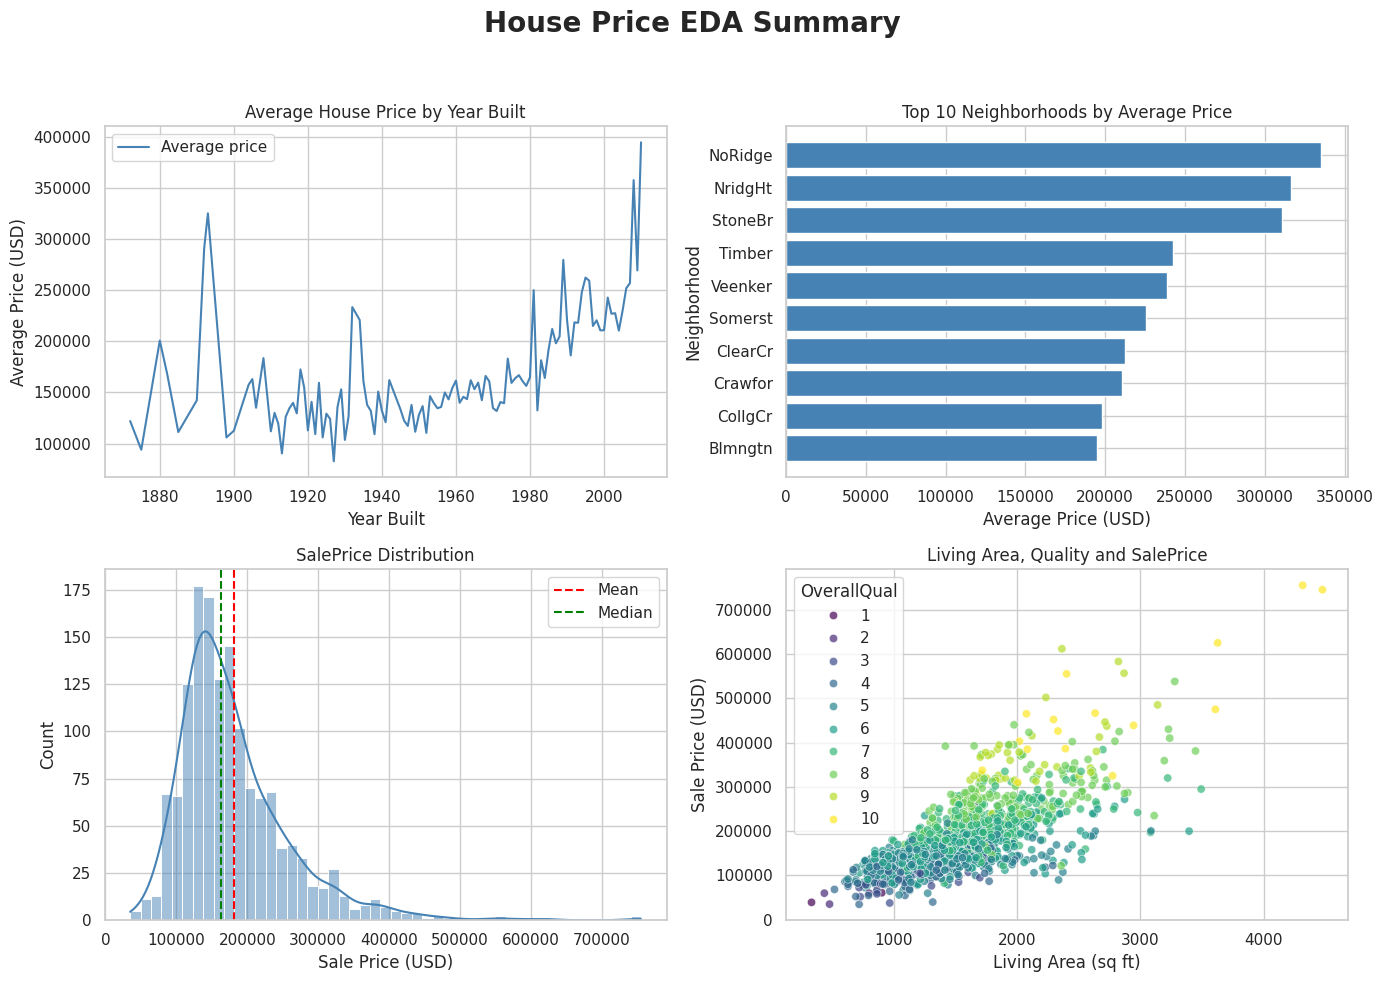

Dashboard saved successfully!


In [20]:
# Create final EDA dashboard
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Panel 1: Average price by construction year
yearly_price = df_clean.groupby("YearBuilt")["SalePrice"].mean()

axes[0, 0].plot(
    yearly_price.index,
    yearly_price.values,
    color="steelblue",
    label="Average price"
)

axes[0, 0].set_title("Average House Price by Year Built")
axes[0, 0].set_xlabel("Year Built")
axes[0, 0].set_ylabel("Average Price (USD)")
axes[0, 0].legend()

# Panel 2: Top 10 neighborhoods
top_neighborhoods = df_clean.groupby(
    "Neighborhood"
)["SalePrice"].mean().nlargest(10).sort_values()

axes[0, 1].barh(
    top_neighborhoods.index,
    top_neighborhoods.values,
    color="steelblue"
)

axes[0, 1].set_title("Top 10 Neighborhoods by Average Price")
axes[0, 1].set_xlabel("Average Price (USD)")
axes[0, 1].set_ylabel("Neighborhood")

# Panel 3: SalePrice distribution
sns.histplot(
    data=df_clean, x="SalePrice",
    kde=True, color="steelblue", ax=axes[1, 0]
)

axes[1, 0].axvline(
    df_clean["SalePrice"].mean(),
    color="red", linestyle="--", label="Mean"
)

axes[1, 0].axvline(
    df_clean["SalePrice"].median(),
    color="green", linestyle="--", label="Median"
)

axes[1, 0].set_title("SalePrice Distribution")
axes[1, 0].set_xlabel("Sale Price (USD)")
axes[1, 0].legend()

# Panel 4: Living area, quality and price
sns.scatterplot(
    data=df_clean,
    x="GrLivArea",
    y="SalePrice",
    hue="OverallQual",
    palette="viridis",
    alpha=0.7,
    legend="full",
    ax=axes[1, 1]
)

axes[1, 1].set_title("Living Area, Quality and SalePrice")
axes[1, 1].set_xlabel("Living Area (sq ft)")
axes[1, 1].set_ylabel("Sale Price (USD)")

# Dashboard title and layout
fig.suptitle(
    "House Price EDA Summary",
    fontsize=20,
    fontweight="bold"
)

plt.tight_layout(rect=[0, 0, 1, 0.95])

# Save dashboard permanently in Google Drive
plt.savefig(
    "/content/drive/MyDrive/eda_dashboard.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Dashboard saved successfully!")

### Dashboard Observations

- Newer houses generally have higher average selling prices.
- NoRidge, NridgHt and StoneBr are among the neighborhoods
  with the highest average selling prices.
- The SalePrice distribution remains positively skewed.
- Larger houses generally have higher selling prices.
- Houses with higher overall quality tend to sell at
  higher prices, even among houses of similar size.

## Final Conclusion

The exploratory data analysis successfully identified
important factors associated with house selling prices.

Overall quality, above-ground living area, garage capacity,
basement area and neighborhood are strongly associated
with SalePrice.

The target variable is right-skewed, and log transformation
makes its distribution more symmetric.

Outlier detection identified unusual observations, while
data cleaning addressed missing values and verified
the quality of the dataset.

The final cleaned dataset contains 1,458 rows and 81 columns.

### Limitations

- Correlation does not establish causation.
- Median imputation may reduce natural variation.
- The excluded unusual sales are not confirmed data errors.
- The findings are specific to the Ames Housing dataset.

This project demonstrates the complete EDA workflow using
statistical analysis, data visualization and data cleaning
without applying machine learning techniques.